# 01-3. 노면온도와 노면상태

01의 4\~5장입니다. 추정 대상인 노면온도가 시각, 계절, 장소에 따라 어떻게 변하는지 보고 정답 라벨인 노면상태(Ice)가 언제 어디서 나오는지 봅니다.

01-2가 저장한 `data/interim/` 자료를 씁니다. 관측소 쌍별 노면온도 차이와 상관은 `data/interim/rwis_pairs.parquet`에 저장해서 01-4의 10장에서 씁니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import warnings

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 한글 글꼴 (설치된 것 중 먼저 찾은 것)
for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
ROUTE_COLORS = {"서해안": PALETTE[0], "호남선": PALETTE[1], "통영-대전중부선": PALETTE[2]}
INK, MUTED = "#0b0b0b", "#898781"
HOLDOUT = list(config.HOLDOUT_STATIONS)
CRS = 5179

In [3]:
# 01-2(3-6)에서 저장한 분석용 자료
rwis = pd.read_parquet(config.INTERIM_DIR / "rwis.parquet")
asos = pd.read_parquet(config.INTERIM_DIR / "asos.parquet")
rwis_st = pd.read_parquet(config.INTERIM_DIR / "stations_rwis.parquet")
asos_st = pd.read_parquet(config.INTERIM_DIR / "stations_asos.parquet")


def to_points(df, lon="경도", lat="위도"):
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs=4326).to_crs(CRS)


xy = lambda g: np.c_[g.geometry.x, g.geometry.y]

rwis_pt, asos_pt = to_points(rwis_st), to_points(asos_st)
st_info = rwis_st.set_index("stn")
D_rs = cdist(xy(rwis_pt), xy(asos_pt)) / 1000  # RWIS-ASOS 거리 (km, 01-2의 2-4)
DAYS = pd.DatetimeIndex(sorted(rwis["time"].dt.normalize().unique()))


def plot_day_heatmap(mat, labels, title, ax, cmap="Blues", vmin=0, vmax=1, cbar_label=""):
    """지점 x 날짜 히트맵 (01-2의 3-1과 같음)."""
    im = ax.imshow(mat, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    month_start = [i for i, d in enumerate(DAYS) if d.day == 1]
    ax.set_xticks(month_start, [DAYS[i].strftime("%y-%m") for i in month_start], fontsize=8)
    ax.axvline(119.5, color=INK, linewidth=1)
    ax.grid(False)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label=cbar_label, fraction=0.02)


print("RWIS:", rwis.shape, "/ ASOS:", asos.shape)

RWIS: (587445, 37) / ASOS: (57600, 32)


## 4. 노면온도

노면온도는 검증 지점의 평가 대상이고 결빙 판단에도 쓰는 변수입니다. 고착 구간(3-4)을 결측으로 처리한 자료를 씁니다.

### 4-1. 관측소별 요약

In [4]:
daily = rwis.groupby(["stn", "date"])["rst"].agg(["min", "max"])
g = rwis.groupby("stn")["rst"]
rst_stats = pd.DataFrame({
    "평균": g.mean(), "표준편차": g.std(), "하위5%": g.quantile(0.05), "최저": g.min(),
    "0°C이하 비율": g.apply(lambda s: (s <= 0).mean()),
    "일교차 평균": (daily["max"] - daily["min"]).groupby("stn").mean(),
    "일최저 평균": daily["min"].groupby("stn").mean(),
    "일최저 0°C이하 날 비율": (daily["min"] <= 0).groupby("stn").mean(),
}).join(st_info[["지점명", "노선", "종류"]]).join(rwis_pt.set_index("stn")["DEM표고"].rename("표고"))
rst_stats.sort_values(["노선", "표고"]).round(2)

,평균,표준편차,하위5%,최저,0°C이하 비율,일교차 평균,일최저 평균,일최저 0°C이하 날 비율,지점명,노선,종류,표고
stn,,,,,,,,,,,,
12209,3.50,6.08,-5.4,-11.8,0.31,10.68,-1.11,0.65,서김제(도),서해안,기본,20.16
12210,5.21,6.64,-4.2,-11.4,0.24,14.91,-0.68,0.60,부안고려청자휴(도),서해안,기본,20.16
12409,3.51,6.47,-6.2,-13.0,0.32,13.78,-2.03,0.70,우곡3교(도),서해안,목표(결빙),20.16
12410,5.79,6.73,-3.6,-10.7,0.21,14.92,-0.01,0.55,부곡교(도),서해안,목표(결빙),20.16
12103,4.70,6.56,-4.6,-12.0,0.26,15.34,-0.36,0.58,군산휴(도),서해안,거점,22.18
12211,4.17,6.48,-5.2,-10.3,0.29,13.79,-1.52,0.68,고인돌휴(도),서해안,기본,60.49
33206,4.44,7.21,-6.0,-11.3,0.30,16.47,-1.82,0.69,용포1교(도),통영-대전중부선,기본,201.64
33409,3.43,6.66,-6.6,-12.6,0.33,14.55,-2.19,0.72,가당2교(도),통영-대전중부선,목표(결빙),230.88
33410,3.34,6.91,-6.6,-11.5,0.36,14.09,-1.76,0.69,삼가2교(도),통영-대전중부선,목표(결빙),399.25


산지인 통영-대전중부선은 시간의 30\~37%, 서해안·호남선은 21\~32%가 노면 0°C 이하입니다. 하루 최저 노면온도가 0°C 이하로 내려가는 날은 전체의 52\~72%입니다. 겨울철에는 대부분의 날에 노면이 영하로 내려가지만 Ice는 드뭅니다(5장). 저온만으로는 결빙을 설명할 수 없습니다.

검증 지점 부곡교와 해전은 같은 노선에서 평균 노면온도가 높은 편입니다.

### 4-2. 일변화

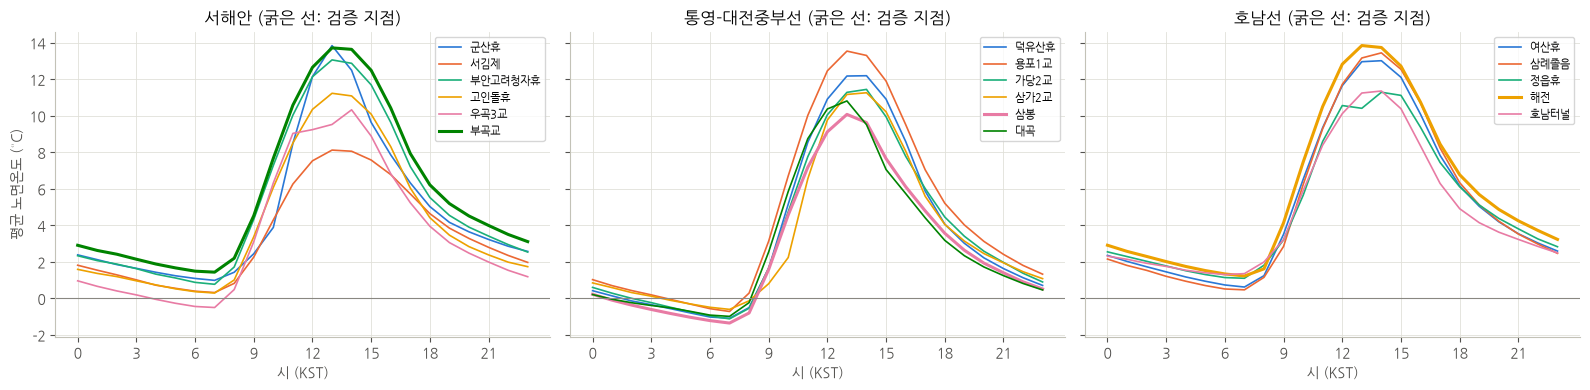

최저 시각: {7: 16, 6: 1} / 최고 시각: {13: 9, 14: 8}
일변화 폭(최고-최저, °C): {'min': 7.8, '50%': 12.3, 'max': 14.3}


In [5]:
diurnal = rwis.pivot_table(index="hour", columns="stn", values="rst", aggfunc="mean")
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, route in zip(axes, config.TARGET_ROUTES):
    for i, stn in enumerate(st_info.index[st_info["노선"] == route]):
        style = {"linewidth": 2.2, "linestyle": "-"} if stn in HOLDOUT else {"linewidth": 1.2}
        ax.plot(diurnal.index, diurnal[stn], color=PALETTE[i], label=st_info.loc[stn, "지점명"].replace("(도)", ""), **style)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title(f"{route} (굵은 선: 검증 지점)")
    ax.set_xlabel("시 (KST)")
    ax.set_xticks(range(0, 24, 3))
    ax.legend(fontsize=8)
axes[0].set_ylabel("평균 노면온도 (°C)")
plt.tight_layout()
plt.show()
print("최저 시각:", diurnal.idxmin().value_counts().to_dict(), "/ 최고 시각:", diurnal.idxmax().value_counts().to_dict())
print("일변화 폭(최고-최저, °C):", (diurnal.max() - diurnal.min()).round(1).describe()[["min", "50%", "max"]].to_dict())

노면온도는 오전 7시에 가장 낮고 13\~14시에 가장 높습니다. 일변화 폭은 지점마다 8\~14°C입니다. 낮 최고온도의 차이(햇빛, 그늘, 포장)가 지점 간 차이의 대부분을 만듭니다. 미관측 지점 추정 오차도 낮에 클 것으로 예상했고 03-1에서 확인했습니다.

### 4-3. 노면온도와 기온의 차이

기온을 같이 재는 기본·거점 관측소 9곳에서 노면온도 - 기온을 봤습니다.

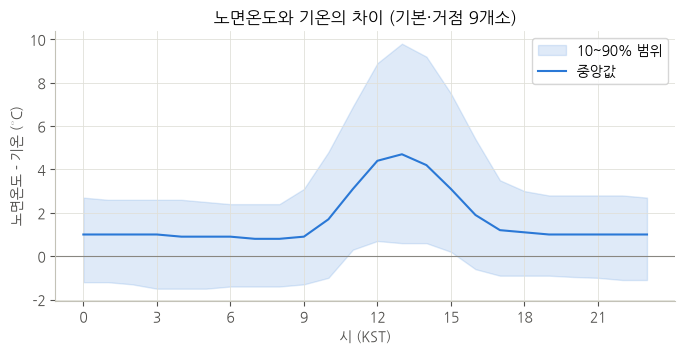

관측소별 평균 (노면-기온): {12103: 1.28, 12209: 0.47, 12210: 1.73, 12211: 0.64, 23202: 1.83, 23203: 1.91, 23204: 1.27, 33103: 2.87, 33206: 2.23}


In [6]:
both = rwis.dropna(subset=["rst", "ta"]).assign(diff=lambda d: d["rst"] - d["ta"])
q = both.groupby("hour")["diff"].quantile([0.1, 0.5, 0.9]).unstack()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.fill_between(q.index, q[0.1], q[0.9], color=PALETTE[0], alpha=0.15, label="10~90% 범위")
ax.plot(q.index, q[0.5], color=PALETTE[0], label="중앙값")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("시 (KST)")
ax.set_ylabel("노면온도 - 기온 (°C)")
ax.set_title("노면온도와 기온의 차이 (기본·거점 9개소)")
ax.legend()
plt.show()
print("관측소별 평균 (노면-기온):", both.groupby("stn")["diff"].mean().round(2).to_dict())

밤에는 노면이 기온보다 1°C 안팎 높고(중앙값) 낮에는 13시 무렵 4\~5°C 높습니다. 관측소별 평균 차이는 0.5\~2.9°C이고 산지의 덕유산휴·용포1교가 큽니다. 밤의 차이가 작아서 보간 기온을 야간 노면온도의 출발점으로 쓸 수 있습니다.

밤에 노면이 기온보다 따뜻한 것은 에너지 수지(0-2)의 지중 열(S)로 설명됩니다. 아래가 공기인 교량은 이 열이 적어서 Jang(2024)의 교량 관측에서는 노면이 기온보다 평균 2°C 넘게 낮았습니다. 이 자료의 교량 관측소는 13-7에서 봅니다.

구름의 영향을 보려고 가장 가까운 ASOS의 전운량으로 밤을 나눴습니다.

In [7]:
nn_asos = dict(zip(rwis_pt["stn"], asos_pt["stn"].values[D_rs.argmin(1)]))
cloud = asos.set_index(["stn", "time"])["전운량(10분위)"]
h = rwis[(rwis["time"].dt.minute == 0)].copy()
h["cloud"] = cloud.reindex(list(zip(h["stn"].map(nn_asos), h["time"]))).to_numpy()
h18 = h[h["hour"] == 18].set_index(["stn", "date"])["rst"]
h06 = h[h["hour"] == 6].assign(date=lambda d: d["date"] - pd.Timedelta("1D")).set_index(["stn", "date"])["rst"]
night_cloud = (h[h["hour"].isin([21, 0, 3])]
               .assign(date=lambda d: np.where(d["hour"] == 21, d["date"], d["date"] - pd.Timedelta("1D")))
               .groupby(["stn", "date"])["cloud"].mean())
cool = pd.concat([h18.rename("18시"), h06.rename("다음날 6시"), night_cloud.rename("야간 운량")], axis=1, sort=True).dropna()
cool["야간 변화"] = cool["다음날 6시"] - cool["18시"]
cool["하늘"] = pd.cut(cool["야간 운량"], [-1, 2, 7, 10], labels=["맑음(0~2)", "구름 조금(3~7)", "흐림(8~10)"])
night_tbl = cool.groupby("하늘")["야간 변화"].describe()[["count", "mean", "25%", "50%", "75%"]]
night_tbl.round(2)

,count,mean,25%,50%,75%
하늘,,,,,
맑음(0~2),1170.0,-7.15,-8.5,-7.3,-6.0
구름 조금(3~7),1414.0,-5.41,-7.1,-5.5,-3.7
흐림(8~10),1434.0,-3.53,-5.4,-3.4,-1.7


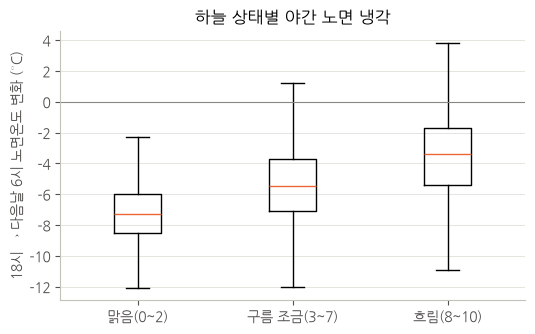

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([cool.loc[cool["하늘"] == k, "야간 변화"] for k in night_tbl.index], tick_labels=night_tbl.index,
           showfliers=False, medianprops={"color": PALETTE[1]})
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_ylabel("18시 → 다음날 6시 노면온도 변화 (°C)")
ax.set_title("하늘 상태별 야간 노면 냉각")
ax.grid(axis="x", visible=False)
plt.show()

맑은 밤에는 노면온도가 하룻밤 사이 평균 7°C 넘게 떨어지고 흐린 밤에는 3\~4°C 떨어집니다. 구름이 노면의 순복사 손실을 줄이기 때문입니다(0-2). 그래서 운량을 야간 노면온도 추정 변수로 넣었습니다. 바람까지 본 대기 안정도별 분석은 13-5에 있습니다.

### 4-4. 계절 변화

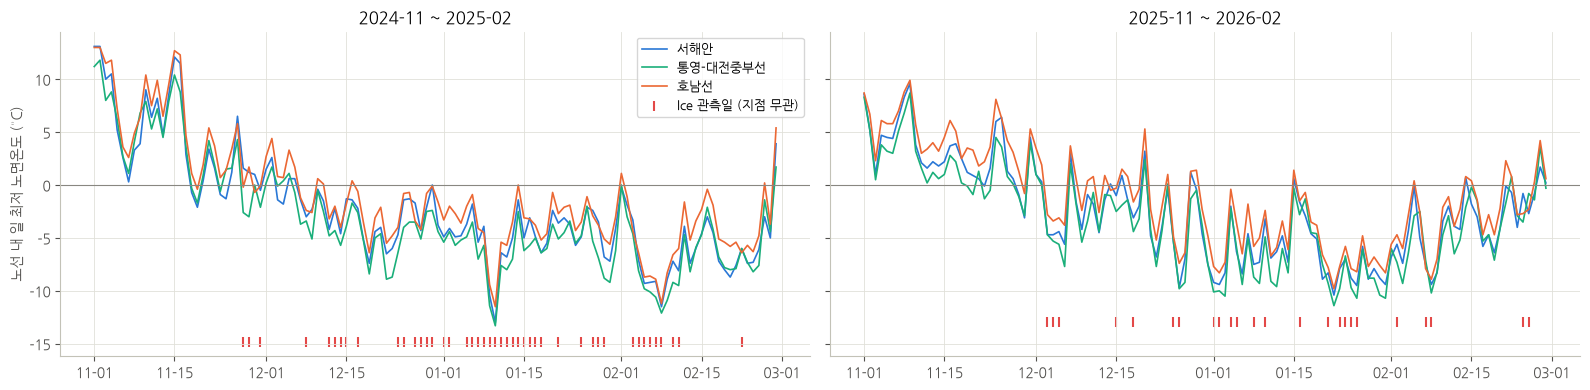

In [9]:
daily_route = rwis.groupby(["노선", "date"])["rst"].min().unstack(0)
ice_by_day = rwis[rwis["ice"] == 1].groupby("date")["stn"].nunique()
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, (start, end) in zip(axes, config.PERIODS):
    part = daily_route.loc[start:end]
    for route in config.TARGET_ROUTES:
        ax.plot(part.index, part[route], color=ROUTE_COLORS[route], linewidth=1.2, label=route)
    ice_d = ice_by_day.loc[start:end]
    ax.scatter(ice_d.index, np.full(len(ice_d), part.min().min() - 1.5), marker="|", s=60, color=PALETTE[7],
               label="Ice 관측일 (지점 무관)")
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title(f"{start[:7]} ~ {end[:7]}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[0].set_ylabel("노선 내 일 최저 노면온도 (°C)")
axes[0].legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
rwis["month"] = rwis["time"].dt.month
monthly = rwis.pivot_table(index="month", columns="노선", values="rst", aggfunc=lambda s: (s <= 0).mean())
monthly.index = [f"{m}월" for m in monthly.index]
monthly.loc[["11월", "12월", "1월", "2월"]].round(3)

노선,서해안,통영-대전중부선,호남선
11월,0.014,0.026,0.001
12월,0.205,0.338,0.167
1월,0.479,0.585,0.437
2월,0.390,0.433,0.344


11월에는 노면이 거의 얼지 않고(0\~3%) 12월부터 영하가 잦아져 1월에 가장 많습니다(시간의 44\~59%). Ice는 일 최저 노면온도가 영하로 내려간 날 가운데 일부에서만 나옵니다(6장).

### 4-5. 영하 지속시간

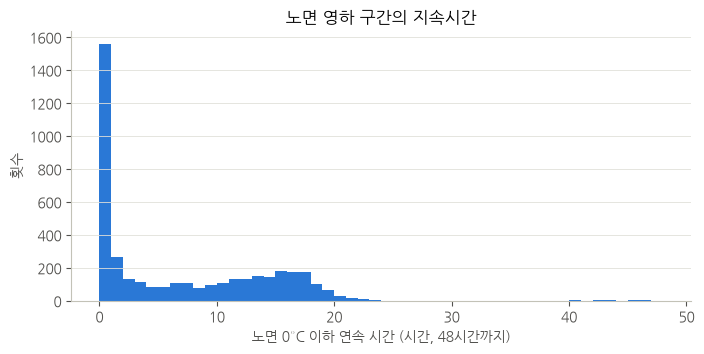

영하 구간 4,068개: 중앙값 3.5시간, 90% 17.0시간, 최장 90.0시간


In [11]:
durations = []
for stn, g in rwis.sort_values(["stn", "time"]).groupby("stn"):
    x = (g["rst"] <= 0).to_numpy().astype(int)
    edge = np.diff(np.r_[0, x, 0])
    durations += list((np.flatnonzero(edge == -1) - np.flatnonzero(edge == 1)) / 6)
durations = pd.Series(durations)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(durations, bins=np.arange(0, 48.5, 1), color=PALETTE[0])
ax.set_xlabel("노면 0°C 이하 연속 시간 (시간, 48시간까지)")
ax.set_ylabel("횟수")
ax.set_title("노면 영하 구간의 지속시간")
ax.grid(axis="x", visible=False)
plt.show()
print(f"영하 구간 {len(durations):,}개: 중앙값 {durations.median():.1f}시간, 90% {durations.quantile(0.9):.1f}시간, "
      f"최장 {durations.max():.1f}시간")

노면 영하는 대부분 몇 시간 이어지는 야간 현상이고(중앙값 3.5시간) 한파 때는 며칠씩 이어집니다(최장 90시간).

### 4-6. 표고와 노면온도

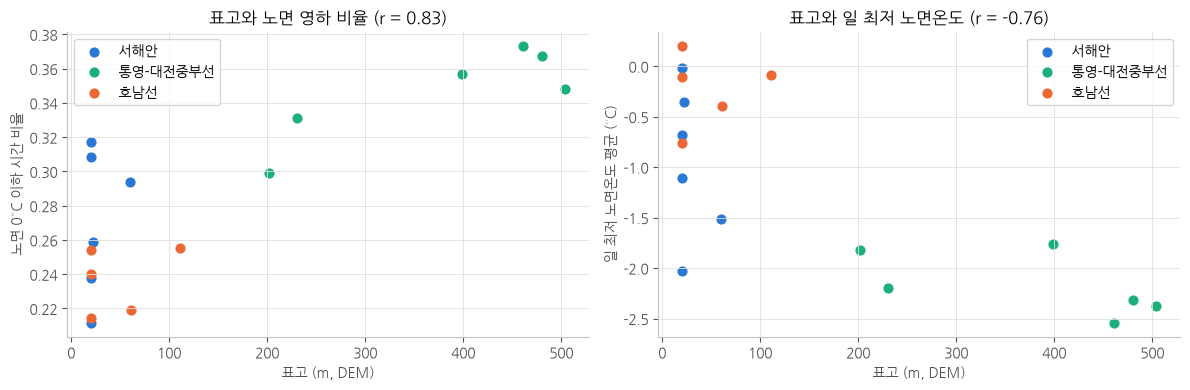

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for route in config.TARGET_ROUTES:
    s = rst_stats[rst_stats["노선"] == route]
    axes[0].scatter(s["표고"], s["0°C이하 비율"], color=ROUTE_COLORS[route], s=40, label=route)
    axes[1].scatter(s["표고"], s["일최저 평균"], color=ROUTE_COLORS[route], s=40, label=route)
for ax, ylabel in zip(axes, ["노면 0°C 이하 시간 비율", "일 최저 노면온도 평균 (°C)"]):
    ax.set_xlabel("표고 (m, DEM)")
    ax.set_ylabel(ylabel)
    ax.legend()
r_le0 = np.corrcoef(rst_stats["표고"], rst_stats["0°C이하 비율"])[0, 1]
r_min = np.corrcoef(rst_stats["표고"], rst_stats["일최저 평균"])[0, 1]
axes[0].set_title(f"표고와 노면 영하 비율 (r = {r_le0:.2f})")
axes[1].set_title(f"표고와 일 최저 노면온도 (r = {r_min:.2f})")
plt.tight_layout()
plt.show()

표고가 높을수록 노면이 자주 영하로 내려가고 더 차가워집니다. 같은 저지대(20m 안팎)에서도 영하 비율은 21\~32%로 벌어집니다. 교량, 그늘, 센서 위치 같은 국지 요인의 영향으로 보입니다.

### 4-7. 관측소 간 노면온도의 공간 상관

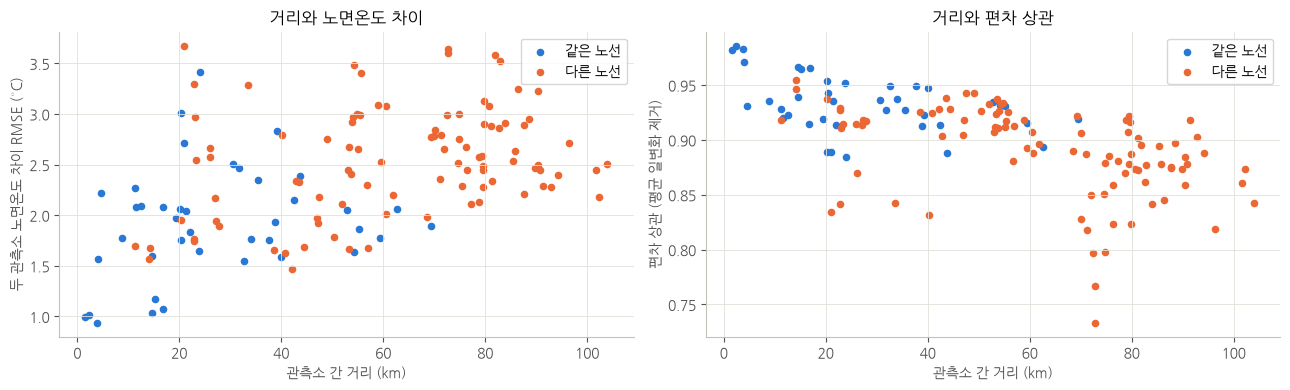

상관         편차상관         RMSE      
            mean count   mean count   mean count
거리                                              
(0, 5]     0.985     5  0.970     5  1.344     5
(5, 10]    0.971     1  0.936     1  1.773     1
(10, 20]   0.972    12  0.938    12  1.693    12
(20, 40]   0.958    30  0.914    30  2.326    30
(40, 80]   0.955    64  0.894    64  2.447    64
(80, 130]  0.951    24  0.874    24  2.712    24

In [13]:
W = rwis.pivot(index="time", columns="stn", values="rst")
anom = W - W.groupby([W.index.month, W.index.hour]).transform("mean")  # 월·시각별 평균 일변화를 뺀 편차
C, CA = W.corr(), anom.corr()
D_all = pd.DataFrame(cdist(xy(rwis_pt), xy(rwis_pt)) / 1000, index=rwis_pt["stn"], columns=rwis_pt["stn"])
pairs = []
for i, a in enumerate(st_info.index):
    for b in st_info.index[i + 1:]:
        pairs.append({"a": a, "b": b, "거리": D_all.loc[a, b], "상관": C.loc[a, b], "편차상관": CA.loc[a, b],
                      "RMSE": np.sqrt(((W[a] - W[b]) ** 2).mean()),
                      "같은노선": st_info.loc[a, "노선"] == st_info.loc[b, "노선"]})
pairs = pd.DataFrame(pairs)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for same, color, label in [(True, PALETTE[0], "같은 노선"), (False, PALETTE[1], "다른 노선")]:
    p = pairs[pairs["같은노선"] == same]
    axes[0].scatter(p["거리"], p["RMSE"], s=20, color=color, label=label)
    axes[1].scatter(p["거리"], p["편차상관"], s=20, color=color, label=label)
axes[0].set_ylabel("두 관측소 노면온도 차이 RMSE (°C)")
axes[1].set_ylabel("편차 상관 (평균 일변화 제거)")
for ax in axes:
    ax.set_xlabel("관측소 간 거리 (km)")
    ax.legend()
axes[0].set_title("거리와 노면온도 차이")
axes[1].set_title("거리와 편차 상관")
plt.tight_layout()
plt.show()
pairs.groupby(pd.cut(pairs["거리"], [0, 5, 10, 20, 40, 80, 130]), observed=True)[["상관", "편차상관", "RMSE"]].agg(["mean", "count"]).round(3)

5km 안의 관측소 쌍은 노면온도 RMSE가 1\~1.5°C이고 20km를 넘으면 2°C 이상입니다. 다만 4.7km 떨어진 군산휴-우곡3교도 RMSE가 2.2°C입니다. 평균 일변화를 뺀 편차 상관은 0.87\~0.97입니다. 한파나 흐림 같은 날씨 변화가 넓은 범위에서 같이 움직입니다.

## 5. 노면상태와 결빙(Ice)

### 5-1. 노면상태 코드

데이터 설명자료 PDF의 코드표입니다.

| 코드 | 상태 | 코드 | 상태 |
|------|------|------|------|
| 1 | Dry | 11 | 노면 위 물이 고여있는 상태 |
| 2 | Wet | 12 | 수막 Damp 이상, 노면온도 1.5도 미만, 제빙제로 결빙 안 됨 |
| 3 | Snow | 13 | 수막 Damp 이상, 노면온도 1.5도 미만, 제빙제 사용으로 결빙 시작 |
| 4 | Ice | 14 | Damp |
| 10 | 저시정 | 15 | 물, 얼음 판별 불가 |

자료에는 코드표에 없는 `0`과 결측 `-999`도 있습니다. 주최 측 답변(QnA 2026-09-30)대로 평가에서 뺍니다. 나머지는 4(Ice)만 결빙(1)이고 그 외는 비결빙(0)입니다.

코드 12·13의 정의에는 "노면온도 1.5°C 미만"과 "제빙제"가 들어 있습니다. 노면센서가 1.5°C를 경계로 판정하고 일부 센서는 제빙제까지 감지하는 것으로 보입니다(13-1, 13-9).

In [14]:
STATE_NAMES = {1: "Dry", 2: "Wet", 3: "Snow", 4: "Ice", 10: "저시정", 11: "물고임",
               12: "Damp+저온(제빙)", 13: "결빙시작(제빙)", 14: "Damp", 15: "판별불가",
               0: "미정의(0)", -999: "결측"}
state_cnt = rwis["노면상태"].value_counts().rename("관측수").to_frame()
state_cnt["상태"] = state_cnt.index.map(STATE_NAMES)
state_cnt["비율(%)"] = (state_cnt["관측수"] / len(rwis) * 100).round(3)
state_cnt

,관측수,상태,비율(%)
노면상태,,,
1,428545,Dry,72.951
2,68499,Wet,11.660
14,68023,Damp,11.579
12,15002,Damp+저온(제빙),2.554
15,4106,판별불가,0.699
3,2245,Snow,0.382
4,303,Ice,0.052
13,290,결빙시작(제빙),0.049
10,242,저시정,0.041


Ice는 전체 58만여 건 중 303건(0.05%)입니다. 결빙과 관련된 상태(Snow, 결빙시작, 판별불가)를 다 합쳐도 1.2% 수준입니다.

### 5-2. 관측소별 노면상태 구성

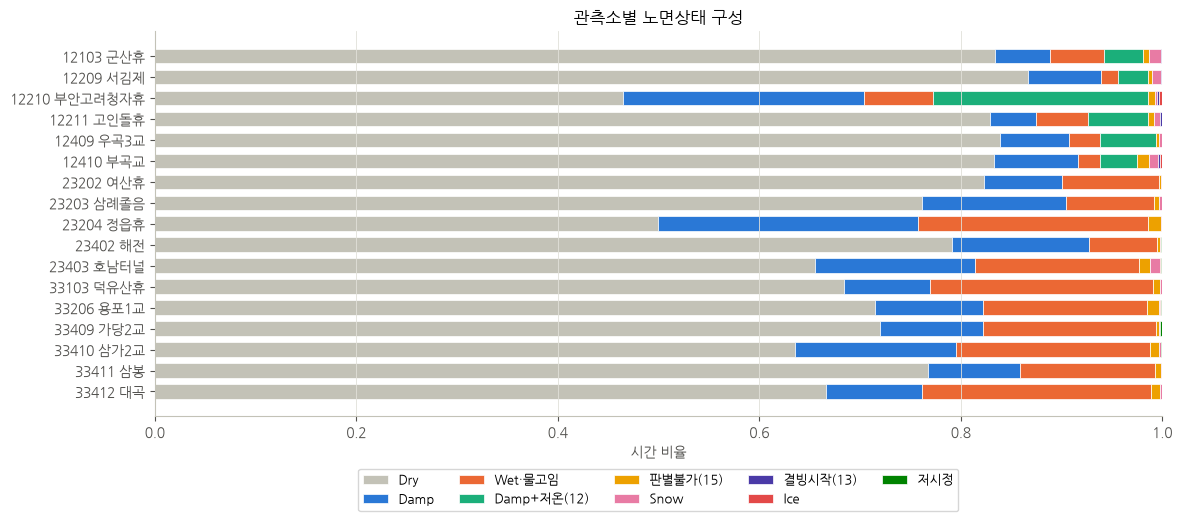

state,Dry,Damp,Wet·물고임,Damp+저온(12),판별불가(15),Snow,결빙시작(13),Ice,저시정
stn,,,,,,,,,
12103,83.44,5.39,5.42,3.86,0.60,1.15,0.13,0.00,0.00
12209,86.66,7.21,1.74,3.01,0.37,0.84,0.12,0.05,0.00
12210,46.44,23.98,6.85,21.29,0.75,0.19,0.16,0.34,0.00
12211,82.92,4.51,5.17,5.94,0.62,0.65,0.17,0.01,0.00
12409,83.89,6.90,3.02,5.57,0.32,0.24,0.05,0.02,0.00
12410,83.33,8.26,2.18,3.74,1.19,0.90,0.21,0.19,0.00
23202,82.28,7.76,9.61,0.00,0.24,0.07,0.00,0.00,0.04
23203,76.13,14.33,8.74,0.00,0.45,0.28,0.00,0.01,0.05
23204,49.96,25.81,22.78,0.00,1.31,0.14,0.00,0.00,0.00


In [15]:
GROUPS = {1: "Dry", 14: "Damp", 2: "Wet·물고임", 11: "Wet·물고임", 12: "Damp+저온(12)", 15: "판별불가(15)",
          3: "Snow", 13: "결빙시작(13)", 4: "Ice", 10: "저시정"}
GROUP_COLORS = {"Dry": "#c3c2b7", "Damp": PALETTE[0], "Wet·물고임": PALETTE[1], "Damp+저온(12)": PALETTE[2],
                "판별불가(15)": PALETTE[3], "Snow": PALETTE[4], "결빙시작(13)": PALETTE[6], "Ice": PALETTE[7],
                "저시정": PALETTE[5]}
comp = pd.crosstab(rwis["stn"], rwis["state"].map(GROUPS), normalize="index")[list(GROUP_COLORS)]
fig, ax = plt.subplots(figsize=(13, 5))
left = np.zeros(len(comp))
labels = [f"{s} {st_info.loc[s, '지점명'].replace('(도)', '')}" for s in comp.index]
for grp, color in GROUP_COLORS.items():
    ax.barh(labels, comp[grp], left=left, color=color, height=0.7, label=grp, edgecolor="white", linewidth=0.5)
    left += comp[grp].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("시간 비율")
ax.set_title("관측소별 노면상태 구성")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
ax.grid(axis="y", visible=False)
plt.show()
(comp * 100).round(2)

제빙제 관련 코드(12, 13)는 서해안선 관측소 6곳에서만 나옵니다. 노선마다 노면센서 종류가 다른 것으로 보이고, 같은 조건에서도 노선에 따라 Ice 판정 빈도가 다를 수 있습니다. 코드 12는 제빙제 때문에 얼지 않은 젖은 노면이므로 제설·제빙 작업도 노면상태에 영향을 줍니다(13-9).

부안고려청자휴(12210)와 정읍휴(23204)는 Dry 비율이 50% 안팎으로 다른 지점(64\~87%)보다 낮고 Damp가 많습니다. 센서 위치나 감도 차이로 보입니다. 부안고려청자휴는 Ice도 가장 많습니다(118건). 통영-대전중부선은 Wet 비율이 13\~23%로 높은 편입니다. 제설제를 뿌린 뒤 젖은 노면이 오래 가는 영향일 수 있습니다.

### 5-3. 상태 전이와 지속시간

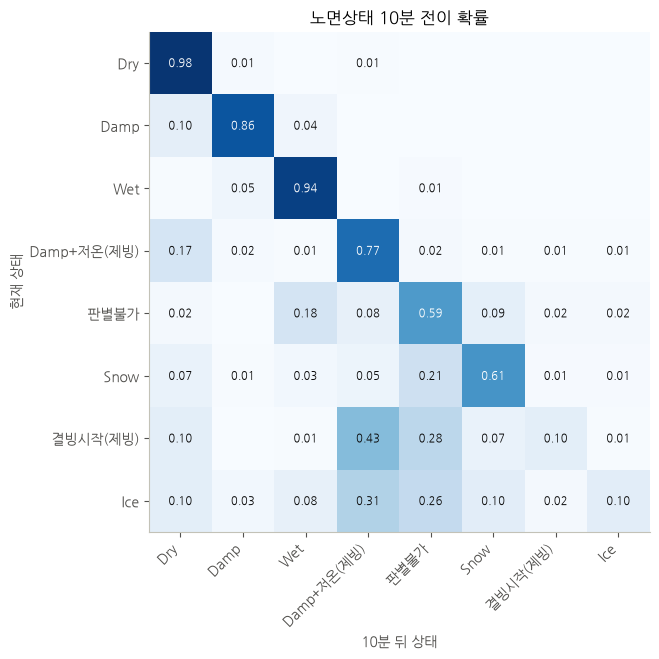

In [16]:
seq = rwis.sort_values(["stn", "time"])
nxt = seq.groupby("stn")["state"].shift(-1)
consecutive = (seq.groupby("stn")["time"].shift(-1) - seq["time"]) == pd.Timedelta("10min")
order = [1, 14, 2, 12, 15, 3, 13, 4]
T = pd.crosstab(seq.loc[consecutive, "state"], nxt[consecutive], normalize="index").reindex(index=order, columns=order)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(T.values, cmap="Blues", vmin=0, vmax=1)
ticks = [STATE_NAMES[s] for s in order]
ax.set_xticks(range(len(order)), ticks, rotation=45, ha="right")
ax.set_yticks(range(len(order)), ticks)
for i in range(len(order)):
    for j in range(len(order)):
        v = T.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else INK)
ax.set_xlabel("10분 뒤 상태")
ax.set_ylabel("현재 상태")
ax.set_title("노면상태 10분 전이 확률")
ax.grid(False)
plt.show()

In [17]:
runs = []
for stn, g in seq.groupby("stn"):
    x = g["state"].to_numpy()
    change = np.r_[True, x[1:] != x[:-1]]
    r = pd.DataFrame({"state": x, "grp": np.cumsum(change)}).groupby("grp").agg(state=("state", "first"), n=("state", "size"))
    runs.append(r)
runs = pd.concat(runs)
run_tbl = (runs.groupby("state")["n"].agg(["count", "mean", "median", "max"]) / [1, 6, 6, 6])
run_tbl.columns = ["연속 구간 수", "평균 지속(시간)", "중앙값(시간)", "최장(시간)"]
run_tbl.rename(index=STATE_NAMES).round(2)

,연속 구간 수,평균 지속(시간),중앙값(시간),최장(시간)
state,,,,
Dry,9705.0,7.29,0.33,517.00
Wet,4346.0,2.63,0.50,83.33
Snow,873.0,0.43,0.17,8.67
Ice,272.0,0.19,0.17,0.67
저시정,22.0,1.83,1.42,5.33
Damp+저온(제빙),3504.0,0.71,0.33,13.50
결빙시작(제빙),261.0,0.19,0.17,0.50
Damp,9687.0,1.17,0.33,34.50
판별불가,1699.0,0.40,0.17,12.00


Dry, Wet, Damp는 10분 뒤에도 같은 상태일 확률이 86\~98%입니다(평균 지속 Dry 7.3시간, Wet 2.6시간). Ice는 10분 뒤에도 Ice일 확률이 10%이고 Damp+저온, 판별불가, Snow, Dry로 흩어집니다. 연속 구간 272개 대부분이 10분 한 번입니다. 판별불가(15), Snow, 결빙시작(13)도 몇십 분 안에 바뀝니다. 젖은 노면이 얼어 가는 동안 센서가 비슷한 상태 사이를 오가는 것으로 보입니다.

### 5-4. Ice 사례의 특성

In [18]:
ice_rows = rwis[rwis["ice"] == 1]
ice_tbl = rwis.groupby("stn").agg(Ice건수=("ice", "sum"))
ice_tbl["Ice일수"] = ice_rows.groupby("stn")["date"].nunique()
ice_tbl["결빙관련 상태 비율(%)"] = rwis.groupby("stn")["state"].apply(lambda s: s.isin([3, 4, 13, 15]).mean() * 100)
ice_tbl = ice_tbl.fillna(0).join(st_info[["지점명", "노선", "종류", "검증지점"]])
ice_tbl.sort_values("Ice건수", ascending=False).round(2)

,Ice건수,Ice일수,결빙관련 상태 비율(%),지점명,노선,종류,검증지점
stn,,,,,,,
12210,118,50.0,1.44,부안고려청자휴(도),서해안,기본,False
12410,64,19.0,2.48,부곡교(도),서해안,목표(결빙),True
23403,47,21.0,2.22,호남터널(도),호남선,목표(결빙),False
33206,28,11.0,1.33,용포1교(도),통영-대전중부선,기본,False
12209,16,12.0,1.37,서김제(도),서해안,기본,False
33103,10,4.0,0.96,덕유산휴(도),통영-대전중부선,거점,False
12409,7,5.0,0.63,우곡3교(도),서해안,목표(결빙),False
23203,5,2.0,0.74,삼례졸음(도),호남선,기본,False
12211,5,4.0,1.45,고인돌휴(도),서해안,기본,False


In [19]:
edges = []
for stn, g in seq.groupby("stn"):
    x = (g["state"] == 4).to_numpy().astype(int)
    e = np.diff(np.r_[0, x, 0])
    edges += list(np.flatnonzero(e == -1) - np.flatnonzero(e == 1))
edges = pd.Series(edges)
print("Ice 연속 길이(10분 단위):", edges.value_counts().sort_index().to_dict(), f"→ 한 번만 나타난 비율 {(edges == 1).mean():.0%}")
print("노선별 Ice:", ice_rows["노선"].value_counts().to_dict(), "/ 종류별 Ice:", ice_rows["종류"].value_counts().to_dict())
print("겨울별 Ice:", ice_rows["winter"].value_counts().to_dict())

Ice 연속 길이(10분 단위): {1: 248, 2: 18, 3: 5, 4: 1} → 한 번만 나타난 비율 91%
노선별 Ice: {'서해안': 211, '호남선': 52, '통영-대전중부선': 40} / 종류별 Ice: {'기본': 172, '목표(결빙)': 120, '거점': 11}
겨울별 Ice: {'2024-25': 231, '2025-26': 72}


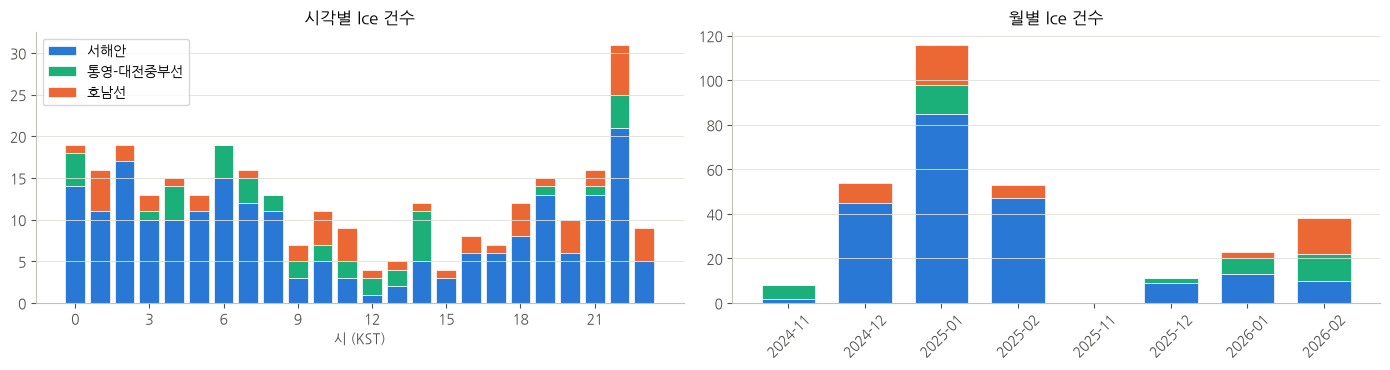

낮 시간(09~17시) Ice 비율: 22%


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
by_hour = pd.crosstab(ice_rows["hour"], ice_rows["노선"]).reindex(index=range(24), columns=config.TARGET_ROUTES, fill_value=0)
bottom = np.zeros(24)
for route in config.TARGET_ROUTES:
    axes[0].bar(by_hour.index, by_hour[route], bottom=bottom, color=ROUTE_COLORS[route], width=0.8, label=route,
                edgecolor="white", linewidth=0.5)
    bottom += by_hour[route].to_numpy()
axes[0].set_xlabel("시 (KST)")
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_title("시각별 Ice 건수")
axes[0].legend()
months = rwis["time"].dt.to_period("M").astype(str)
by_month = pd.crosstab(months[rwis["ice"] == 1], ice_rows["노선"]).reindex(
    index=sorted(months.unique()), columns=config.TARGET_ROUTES, fill_value=0)
bottom = np.zeros(len(by_month))
for route in config.TARGET_ROUTES:
    axes[1].bar(by_month.index, by_month[route], bottom=bottom, color=ROUTE_COLORS[route], width=0.7, label=route,
                edgecolor="white", linewidth=0.5)
    bottom += by_month[route].to_numpy()
axes[1].set_title("월별 Ice 건수")
axes[1].tick_params(axis="x", rotation=45)
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(f"낮 시간(09~17시) Ice 비율: {ice_rows['hour'].between(9, 17).mean():.0%}")

Ice의 70%는 서해안선에서, 76%는 2024-25 겨울에 나왔고 2025-11에는 Ice가 없습니다. 서해안선 Ice는 밤(21\~08시)에 몰려 있고 통영-대전·호남선은 낮에도 나옵니다. 낮 시간 Ice는 전체의 20% 남짓입니다.

### 5-5. Ice 발생일 달력과 동시성

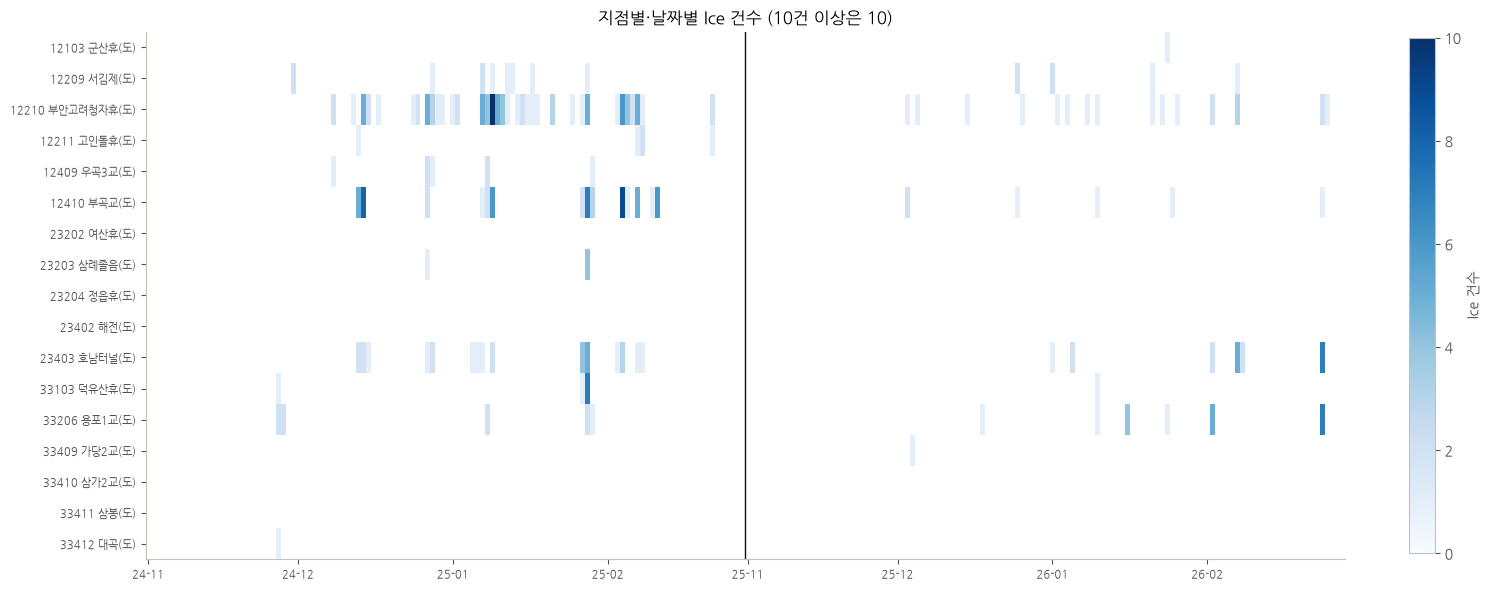

In [21]:
cal = (rwis.groupby(["stn", "date"])["ice"].sum().unstack().reindex(index=rwis_st["stn"], columns=DAYS).fillna(0))
fig, ax = plt.subplots(figsize=(15, 6))
plot_day_heatmap(np.where(cal.values > 0, np.minimum(cal.values, 10), np.nan),
                 [f"{s} {n}" for s, n in zip(rwis_st["stn"], rwis_st["지점명"])],
                 "지점별·날짜별 Ice 건수 (10건 이상은 10)", ax, vmin=0, vmax=10, cbar_label="Ice 건수")
plt.tight_layout()
plt.show()

In [22]:
ice_days = ice_rows.groupby("stn")["date"].apply(set)
same_day = ice_rows.groupby("date")["stn"].nunique()
sd = ice_rows.groupby(["stn", "date"]).size().reset_index()
sd["다른지점"] = sd["date"].map(same_day) - 1
print(f"Ice가 1건 이상 있었던 날: {len(same_day)}일 / 240일")
print(f"지점-일 기준으로 같은 날 다른 지점에도 Ice가 있었던 비율: {(sd['다른지점'] > 0).mean():.0%}")
jac = []
for i, a in enumerate(ice_days.index):
    for b in ice_days.index[i + 1:]:
        inter = len(ice_days[a] & ice_days[b])
        if inter:
            jac.append({"지점A": st_info.loc[a, "지점명"], "지점B": st_info.loc[b, "지점명"], "함께 Ice인 날": inter,
                        "Jaccard": inter / len(ice_days[a] | ice_days[b]), "거리(km)": D_all.loc[a, b]})
pd.DataFrame(jac).sort_values("Jaccard", ascending=False).head(10).round(2)

Ice가 1건 이상 있었던 날: 69일 / 240일
지점-일 기준으로 같은 날 다른 지점에도 Ice가 있었던 비율: 70%


,지점A,지점B,함께 Ice인 날,Jaccard,거리(km)
22,부곡교(도),호남터널(도),10,0.33,20.30
12,부안고려청자휴(도),호남터널(도),15,0.27,22.89
31,덕유산휴(도),대곡(도),1,0.25,12.61
30,덕유산휴(도),용포1교(도),3,0.25,19.40
10,부안고려청자휴(도),부곡교(도),13,0.23,3.81
5,서김제(도),호남터널(도),6,0.22,40.26
24,부곡교(도),용포1교(도),5,0.20,90.78
26,삼례졸음(도),덕유산휴(도),1,0.20,53.04
18,우곡3교(도),삼례졸음(도),1,0.17,23.40
23,부곡교(도),덕유산휴(도),3,0.15,86.44


Ice는 240일 중 69일에 나왔고 그중 70%는 여러 지점에서 같은 날 나타납니다. 같은 날 Ice가 나오는 쌍에는 가까운 쌍(부안고려청자휴-부곡교 3.8km)도 있고 20km 넘게 떨어진 서해안선-호남선 남부 쌍도 있습니다. 강설이나 한파 같은 지역 기상의 영향으로 보입니다.

하루 단위로는 주변 RWIS의 Ice·Snow 정보가 미관측 지점 판단에 쓸모 있어 보입니다. 다만 다른 학습 지점의 같은 시각 노면상태는 입력으로 쓸 수 없어서(QnA 2026-11-02) 모델에 넣지 않았습니다.

### 5-6. 노면상태별 노면온도

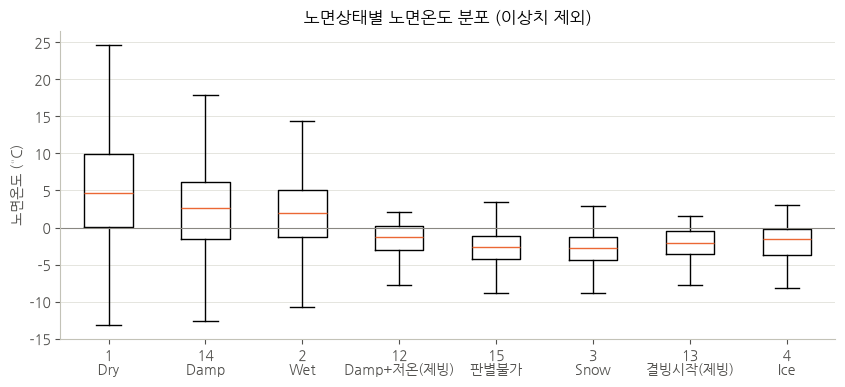

,count,mean,std,min,25%,50%,75%,max
state,,,,,,,,
Dry,424621.0,5.24,6.98,-13.2,0.10,4.6,9.90,33.1
Wet,68499.0,2.10,5.17,-13.3,-1.30,1.9,5.00,22.0
Snow,2245.0,-2.86,2.23,-8.9,-4.40,-2.7,-1.30,7.5
Ice,303.0,-2.04,2.47,-9.8,-3.65,-1.6,-0.15,3.0
Damp+저온(제빙),15002.0,-1.60,2.26,-11.4,-3.00,-1.3,0.20,2.1
결빙시작(제빙),290.0,-2.12,2.22,-10.1,-3.60,-2.1,-0.50,1.5
Damp,68022.0,2.63,5.69,-12.6,-1.60,2.6,6.20,30.1
판별불가,4106.0,-2.67,2.24,-11.1,-4.30,-2.6,-1.10,3.7


In [23]:
valid = rwis[rwis["state"].isin(order) & rwis["rst"].notna()]
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([valid.loc[valid["state"] == s, "rst"] for s in order], tick_labels=[f"{s}\n{STATE_NAMES[s]}" for s in order],
           showfliers=False, medianprops={"color": PALETTE[1]})
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_ylabel("노면온도 (°C)")
ax.set_title("노면상태별 노면온도 분포 (이상치 제외)")
ax.grid(axis="x", visible=False)
plt.show()
valid.groupby("state")["rst"].describe().round(2).rename(index=STATE_NAMES)

In [24]:
cold = valid[valid["rst"] <= 0]
print(f"노면온도 0°C 이하 관측 {len(cold):,}건 중 Ice {cold['state'].eq(4).sum()}건 ({cold['state'].eq(4).mean() * 100:.2f}%)")
print(cold["state"].map(STATE_NAMES).value_counts().to_string())

노면온도 0°C 이하 관측 168,775건 중 Ice 236건 (0.14%)
state
Dry            105746
Damp            23178
Wet             22950
Damp+저온(제빙)     10784
판별불가             3605
Snow             2041
Ice               236
결빙시작(제빙)          235


Ice일 때 노면온도 중앙값은 -1.6°C이고 90%가 1°C 이하입니다. Snow, 결빙시작, 판별불가도 비슷한 온도대입니다. 반대로 노면이 0°C 이하인 시간의 63%는 Dry이고 Ice는 0.14%입니다.

## 저장

4-7의 관측소 쌍별 노면온도 차이와 상관을 01-4의 10장에서 쓰도록 저장합니다.

In [25]:
pairs.to_parquet(config.INTERIM_DIR / "rwis_pairs.parquet", index=False)
print(pairs.shape)

(136, 7)
